# 02 — LeNet-style CNN

In [1]:
# Standard imports
from datetime import datetime
from pathlib import Path
import sys
from uuid import uuid4
from zoneinfo import ZoneInfo

# Third-party imports
import pandas as pd
import torch

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

# Local imports
from scripts.dataset.digit_dataset_config import PIXEL_COLUMNS
from scripts.dataset.digit_dataset_helpers import load_datasets
from scripts.model.digit_model_helpers import (
    LeNet,
    build_data_loaders,
    inspect_last_validation_prediction,
    plot_training_history,
    seed_training,
    train_model,
)
from scripts.model.digit_model_metrics import (
    build_per_digit_metrics,
    plot_misclassified_digit,
    plot_validation_confusion_matrix,
)


## Start by loading the data and inspecting the model.

In [2]:
datasets = load_datasets()
train = datasets["train"]
test = datasets["test"]
print(f"Training shape: {train.shape}")
print(f"Test shape: {test.shape}")

Training shape: (42000, 785)
Test shape: (28000, 784)


## Our Simplified LeNet style model uses:
- two convolution and average-pooling stages, 
- followed by dense layers with ten outputs. 
- tanh activations
- Padding the first convolution accommodates 28 × 28 inputs.

This follows the LeNet design with fully connected convolution channels and a linear classification output.

In [3]:
model = LeNet()
print(model)

LeNet(
  (network): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=400, out_features=120, bias=True)
    (8): Tanh()
    (9): Linear(in_features=120, out_features=84, bias=True)
    (10): Tanh()
    (11): Linear(in_features=84, out_features=10, bias=True)
  )
)


Pass the first five training images through the model to check that the output shape is `(5, 10)`: five images, each with ten digit scores.

In [4]:
images = torch.tensor(
    train[PIXEL_COLUMNS].iloc[:5].to_numpy(), dtype=torch.float32
).reshape(-1, 1, 28, 28) / 255.0

with torch.no_grad():
    outputs = model(images)
print(f"Output shape: {tuple(outputs.shape)}")

Output shape: (5, 10)


## Training setup

Use a fixed, stratified 80/20 split of the labeled data. Train with Adam
(learning rate 0.001), batches of 64, and 10 epochs.


In [5]:
SEED = 42
VALIDATION_FRACTION = 0.2
BATCH_SIZE = 64
LEARNING_RATE = 0.001
EPOCHS = 10

seed_training(SEED)

### Split the labeled data and build data loaders

In [6]:
train_loader, val_loader = build_data_loaders(
    train,
    validation_fraction=VALIDATION_FRACTION,
    batch_size=BATCH_SIZE,
    seed=SEED,
)
print(f"Training images: {len(train_loader.dataset):,}")
print(f"Validation images: {len(val_loader.dataset):,}")

Training images: 33,600
Validation images: 8,400


### Train and validate


In [7]:
seed_training(SEED)
train_loader.generator.manual_seed(SEED)
model = LeNet()

# Using reduction="none" will return a tensor containing the individual loss values,
# one for each image in the batch. that let's us use .mean() for backpropagation 
# and .sum() to accumulate the epoch's total loss.
loss_function = torch.nn.CrossEntropyLoss(reduction="none")


run_id = datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%d_%H%M%S") + "_" + uuid4().hex[:8]
checkpoint_path = project_root / "data" / "models" / f"lenet_{run_id}_best.pt"

model, history, best_epoch, best_val_logits, best_val_labels = train_model(
    model, train_loader, val_loader, loss_function,
    epochs=EPOCHS, checkpoint_path=checkpoint_path,
    learning_rate=LEARNING_RATE,
)

# Keep each run's best validation outputs for comparison with future runs.
validation_outputs_dir = project_root / "data" / "validation_outputs"
validation_outputs_dir.mkdir(parents=True, exist_ok=True)
validation_outputs_path = validation_outputs_dir / f"lenet_{run_id}_validation.pt"
torch.save({
    "run_id": run_id,
    "checkpoint_path": str(checkpoint_path),
    "logits": best_val_logits.detach().cpu(),
    "labels": best_val_labels.detach().cpu(),
    "best_epoch": best_epoch,
    "seed": SEED,
    "validation_fraction": VALIDATION_FRACTION,
}, validation_outputs_path)
print(f"Validation outputs saved to: {validation_outputs_path}")


Training device: mps
Epoch 01/10 | train loss 0.4031, accuracy 88.21% | val loss 0.1785, accuracy 94.50%
Epoch 02/10 | train loss 0.1304, accuracy 96.04% | val loss 0.1170, accuracy 96.36%
Epoch 03/10 | train loss 0.0822, accuracy 97.46% | val loss 0.0842, accuracy 97.44%
Epoch 04/10 | train loss 0.0606, accuracy 98.11% | val loss 0.0836, accuracy 97.49%
Epoch 05/10 | train loss 0.0468, accuracy 98.56% | val loss 0.0715, accuracy 97.85%
Epoch 06/10 | train loss 0.0386, accuracy 98.76% | val loss 0.0682, accuracy 97.83%
Epoch 07/10 | train loss 0.0312, accuracy 99.03% | val loss 0.0679, accuracy 98.21%
Epoch 08/10 | train loss 0.0253, accuracy 99.23% | val loss 0.0609, accuracy 98.24%
Epoch 09/10 | train loss 0.0207, accuracy 99.40% | val loss 0.0661, accuracy 98.14%
Epoch 10/10 | train loss 0.0179, accuracy 99.42% | val loss 0.0636, accuracy 98.07%
Restored epoch 8: validation loss 0.0609
Best weights saved to: /Users/KurtMeehanPro/Documents/code/git/digit-recognizer/data/models/lenet_

### Review learning curves

,epoch,train_loss,val_loss,train_accuracy,val_accuracy
0,1,0.403131,0.178505,0.882083,0.945000
1,2,0.130444,0.116965,0.960387,0.963571
2,3,0.082163,0.084174,0.974554,0.974405
3,4,0.060606,0.083629,0.981131,0.974881
4,5,0.046849,0.071505,0.985565,0.978452
5,6,0.038564,0.068170,0.987589,0.978333
6,7,0.031217,0.067908,0.990298,0.982143
7,8,0.025272,0.060903,0.992292,0.982381
8,9,0.020709,0.066132,0.993988,0.981429
9,10,0.017883,0.063577,0.994167,0.980714


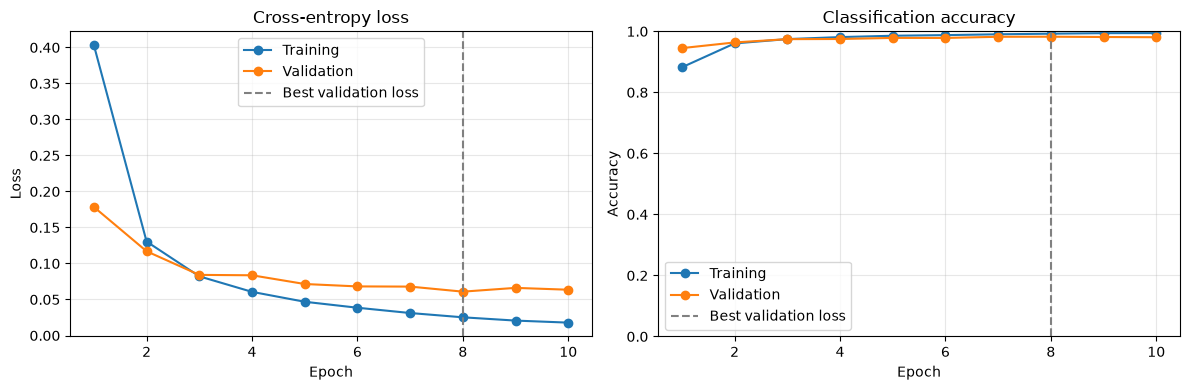

In [8]:
history_df = pd.DataFrame(history)
display(history_df)
fig = plot_training_history(history_df, best_epoch)

### Validation confusion matrix

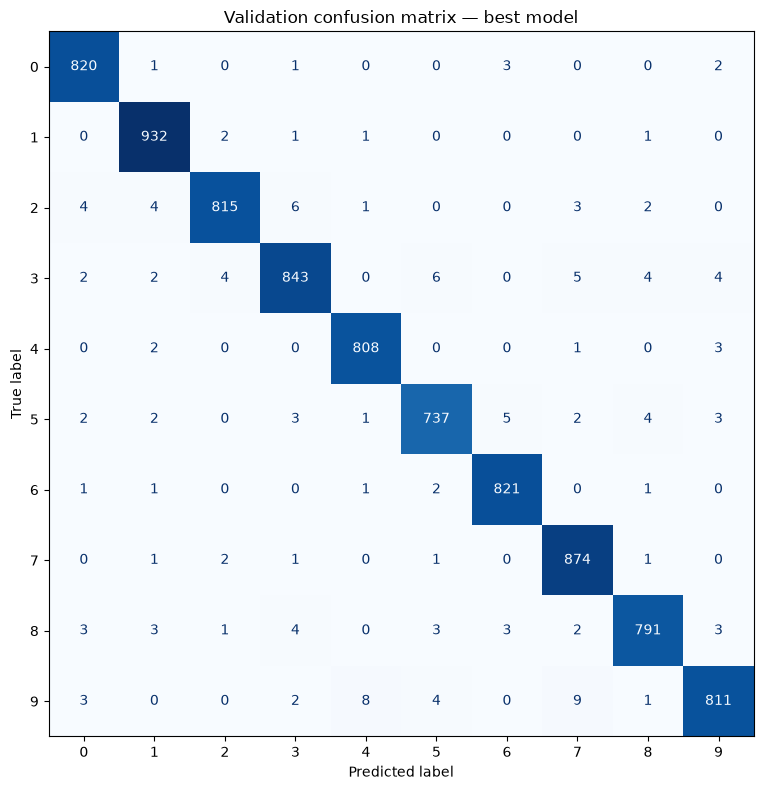

In [9]:
val_confusion_matrix, confusion_fig = plot_validation_confusion_matrix(model, val_loader)

In [10]:
per_digit_metrics = build_per_digit_metrics(val_confusion_matrix).sort_values("F1")
display(per_digit_metrics.style.format({
    "Precision": "{:.2%}",
    "Recall": "{:.2%}",
    "F1": "{:.2%}",
    "Accuracy": "{:.2%}",
}))

,Count,Correctly Predicted,Incorrectly Predicted,Precision,Recall,F1,Accuracy
Digit,,,,,,,
3,870,843,27,97.91%,96.90%,97.40%,99.46%
9,838,811,27,98.18%,96.78%,97.48%,99.50%
5,759,737,22,97.88%,97.10%,97.49%,99.55%
8,813,791,22,98.26%,97.29%,97.78%,99.57%
2,835,815,20,98.91%,97.60%,98.25%,99.65%
7,880,874,6,97.54%,99.32%,98.42%,99.67%
0,827,820,7,98.20%,99.15%,98.68%,99.74%
1,937,932,5,98.31%,99.47%,98.89%,99.75%
4,814,808,6,98.54%,99.26%,98.90%,99.79%


### Misclassified validation threes

Show every actual three that the restored best model predicted as another digit.
Each image is labeled with the model’s prediction.


Actual digit 3: 27 misclassified validation images


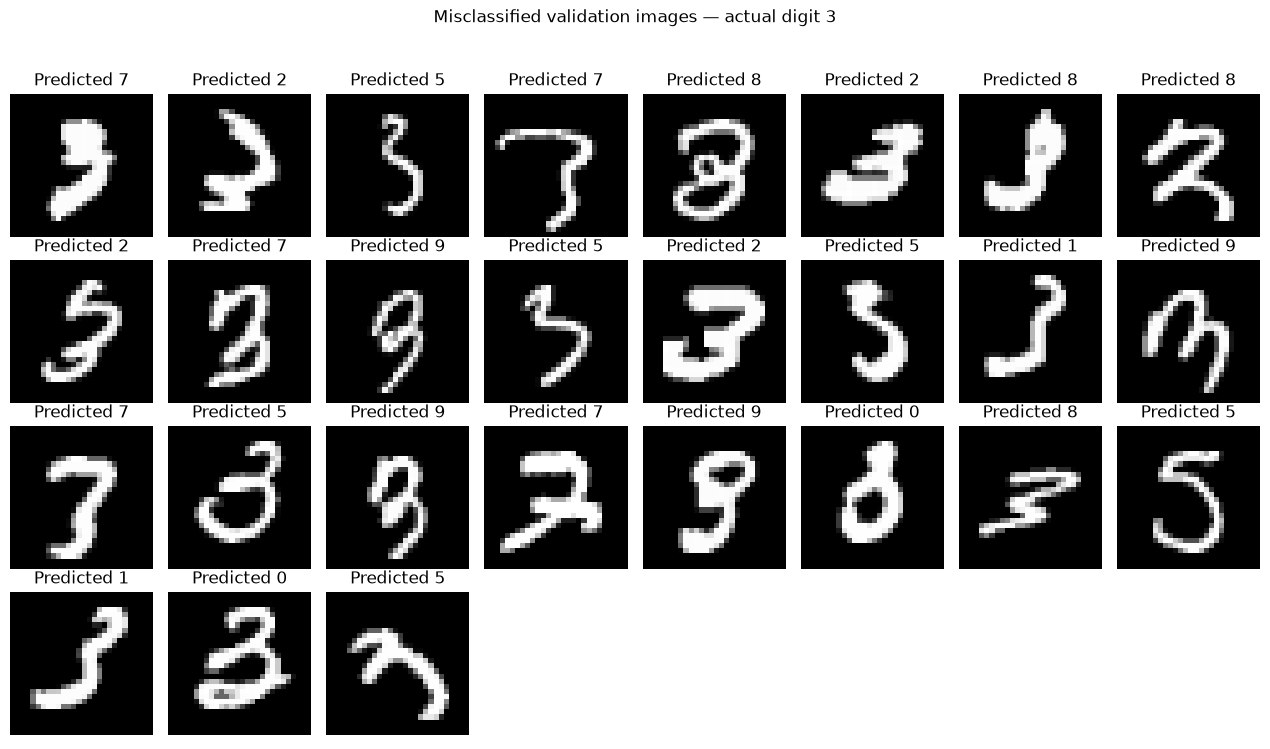

In [11]:
misclassified_threes_fig = plot_misclassified_digit(model, val_loader, digit=3)

### Inspect the last validation prediction

Show the final validation image’s ten logits and softmax probabilities from the best epoch.


In [12]:
actual_digit, predicted_digit, last_prediction_scores = inspect_last_validation_prediction(
    best_val_logits, best_val_labels
)
print(f"Actual digit: {actual_digit} | Predicted digit: {predicted_digit}")
display(last_prediction_scores.style.format({"Logit": "{:.4f}", "Probability": "{:.2%}"}))

Actual digit: 1 | Predicted digit: 1


,Logit,Probability
Digit,,
0,-3.5593,0.00%
1,11.6190,99.99%
2,-5.5056,0.00%
3,-1.9333,0.00%
4,1.0670,0.00%
5,-1.3293,0.00%
6,-2.4036,0.00%
7,0.5479,0.00%
8,1.8691,0.01%
